# The population balance as the expectation of particle replacement, and the parcels the sampling needs

**Question:** Is the Whiten product the expectation of the particle-replacement rule that discrete-element crusher models use, and how many sampled parcels does that rule need to reproduce it within one percent of the mass?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say what the particle-replacement family of discrete-element crusher models does, and which part of it the population balance stands for;
- derive on paper that the expectation of the replacement rule is the Whiten product, and say why a run can then only measure sampling error;
- run the pipeline's replacement walk with the product's own selection and breakage, and read how its error shrinks as the number of parcels grows;
- state plainly what this comparison can say about discrete-element models and what it cannot.

## Setup

Numpy and matplotlib. The random draws come from numpy's generator with a fixed seed, so every run gives the same numbers.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the pieces of notebook 02 and the two pipeline functions that make this notebook possible: `assemble_chamber`, which builds the selection and the breakage of an operating point as the engine does, and `replacement_walk`, the particle-replacement rule itself. Both live in `data-pipeline/pipeline/model/crusher/whiten.py` next to the Whiten solver, so the notebook defines no method of its own.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.whiten import assemble_chamber, replacement_walk, whiten_solve
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.linalg import solve_lu
from pipeline.model.crusher.sieve import size_at_passing, to_psd
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The reference case S01. No discrete-element code or data is committed to this repository, and the SDD lists discrete-element simulation as not a method of this release, so the literature below is cited and not run. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads S01 and runs the engine once to get the feed distribution on the grid.

In [2]:
# Read S01, run the engine once for its feed, and fix the grid
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
result = evaluate(op)
edges, mids = grid_edges(), np.array(grid_mid())
K = len(mids)
feed = np.array(result.feed.mass)

print("classes:", K, "| feed mass:", feed.sum().round(12), "| engine P80:", round(result.p80, 3), "mm")

classes: 28 | feed mass: 1.0 | engine P80: 27.698 mm


## Method

**Step 1, where the rule comes from.** The method that resolves the mechanism of a crusher is the discrete element method, which resolves the particles, their contacts and their breakage in the chamber's geometry. Two families are in the sources the product cites. In **particle replacement**, a particle that meets a breakage criterion is deleted and replaced by a set of smaller fragments sized from a breakage-function distribution; Cleary and Sinnott (2015; https://doi.org/10.1016/j.mineng.2014.10.021) develop it for compression crushers. In the **bonded-particle** family the rock is an assembly of sub-particles and the fracture emerges from the bond model; Quist and Evertsson (2016; https://doi.org/10.1016/j.mineng.2015.11.004) calibrate it to single-particle breakage for a cone crusher. Both are offline tools that resolve every particle and every contact of the chamber, a computation neither paper reports in a form this notebook can quote or rerun, which is why the population balance is the fast approximation the studio runs live.

What can be run here, and what cannot, has to be said exactly. Neither family's code or data is in this repository, so none of their numbers is reproduced, and this is why the topic has no level 3 notebook. What the replacement family shares with the balance is a stochastic reading of the same two functions: a particle that is selected is replaced by fragments drawn from the appearance distribution, and a fragment that is still selected is broken again. That rule can be run on the product's own selection $C$ and breakage $B$, with each unit of mass as a parcel so that the walk stays linear in mass.

**Step 2, the expectation on paper.** Let $f$ be the feed distribution over the classes and let $n_k$ be the expected share of the feed that is inside the chamber at pass $k$, so $n_0 = f$. In each pass a parcel of class $j$ is nipped with probability $c_j$ and replaced by a parcel of class $i$ with probability $B_{ij}$; the parcels that are not nipped leave as product. In expectation, $n_{k+1} = B\,C\,n_k$ and the product collects $(I - C)\,n_k$ at every pass, so

$$\mathbb{E}[p] = (I - C)\sum_{k \ge 0} (B C)^k f = (I - C)(I - B C)^{-1} f$$

which is the Whiten product of notebook 02 (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). The series is finite, since $BC$ is strictly lower triangular and every replacement lands on a finer class. The consequence is the point of this notebook: agreement between the walk and the balance is an identity, not a finding. A run cannot test whether the replacement rule describes a crusher; it can only measure how large the sampling error of a walk of $N$ parcels is, and that is the practical question, because the walk is the cheap stand-in for a simulation that costs hours.

**Step 3, the model.** The cell asks `assemble_chamber` for the selection vector $c$ and the breakage matrix $B$ of S01, solves the balance with the engine's Whiten solver and reads the reference product. It prints the sizes that are selected by chance, the classes that are always and never nipped, the product P80 and the share of the product mass above the 22.627 mm class edge (the square-root-of-two grid has edges at 32.0, 22.627 and 16.0 mm, so this is the edge closest to 20 mm), the two numbers the walk has to reproduce.

In [3]:
# Ask the pipeline for c and B of S01, solve the balance, and read the reference product
c, B = assemble_chamber(op)
reference = np.array(whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K).product)
by_chance = mids[(c > 0) & (c < 1)]
coarse = [i for i in range(K) if edges[i + 1] >= 19.9]
balance_p80 = size_at_passing(to_psd(edges, reference.tolist()), 0.8)
print("class mid-sizes selected with probability between 0 and 1 [mm]:", np.round(by_chance, 1))
print("always nipped (C = 1):", int((c == 1).sum()), "classes | never nipped (C = 0):", int((c == 0).sum()), "classes")
coarse_share = float(reference[coarse].sum())
print("balance P80 [mm]:", round(balance_p80, 3), f"| mass above the {edges[coarse[-1] + 1]:.3f} mm edge:",
      round(coarse_share, 4))

class mid-sizes selected with probability between 0 and 1 [mm]: [53.8 38.1]
always nipped (C = 1): 4 classes | never nipped (C = 0): 22 classes
balance P80 [mm]: 27.698 | mass above the 22.627 mm edge: 0.2965


**Step 4, the replacement walk.** `replacement_walk` draws the feed parcels from the feed distribution, then repeats a single rule until no parcel is left in the chamber: each parcel of class $j$ is nipped with probability $c_j$, and a nipped parcel is replaced by a parcel of class $i$ drawn with probability $B_{ij}$; a parcel that is not nipped leaves and is counted in the product. The loop works on counts of parcels per class, so each pass is a binomial draw per class and a multinomial draw per nipped class, and it ends because every replacement lands strictly on a finer class. It is seeded and returns the product as a distribution together with the mean number of nips a parcel suffered. The cell runs one walk of 200 000 parcels and prints how far it lands from the balance.

In [4]:
# One walk of 200 000 parcels, seeded, against the balance
walk, nips_per_parcel = replacement_walk(c, B, feed, 200_000, 42)
print("largest class-mass difference to the Whiten product:", np.abs(walk - reference).max().round(5))
print("total variation distance:", (0.5 * np.abs(walk - reference).sum()).round(5))
walk_p80 = size_at_passing(to_psd(edges, walk.tolist()), 0.8)
print("P80 [mm], walk against balance:", round(walk_p80, 3), round(balance_p80, 3))
print("mass above the coarse edge, walk against balance:", round(float(walk[coarse].sum()), 4), round(coarse_share, 4))

largest class-mass difference to the Whiten product: 0.00168
total variation distance: 0.00372
P80 [mm], walk against balance: 27.784 27.698
mass above the coarse edge, walk against balance: 0.2976 0.2965


The walk with 200 000 parcels lands within 0.17 percentage points of the balance in every class, and it reproduces the two numbers of Step 3: a P80 of 27.784 mm against the balance's 27.698 mm, and 0.2976 of the product mass above the 22.627 mm edge against 0.2965. The figure lays the two products over each other class by class. Both are zero in the coarse classes that are always nipped, and both put the bulk of their mass between 5 and 40 mm.

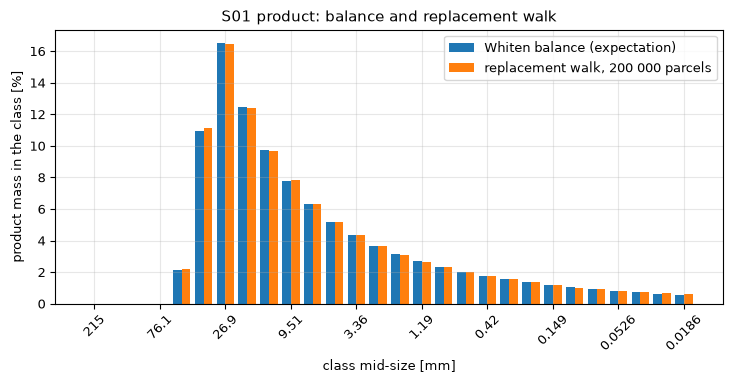

In [5]:
# Bar chart of the Whiten product and the replacement-walk product per class
position = np.arange(K)
fig, ax = plt.subplots()
ax.bar(position - 0.2, reference * 100, 0.4, label="Whiten balance (expectation)")
ax.bar(position + 0.2, walk * 100, 0.4, label="replacement walk, 200 000 parcels")
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("class mid-size [mm]")
ax.set_ylabel("product mass in the class [%]")
ax.set_title("S01 product: balance and replacement walk")
ax.legend()
fig.tight_layout()
plt.show()

The bars agree to the eye in every class, as the algebra of Step 2 says they must: the balance is the expectation of the walk, and the walk is a sampling of the balance. The picture cannot show the quality of the agreement, since a 0.17-point difference is below the resolution of the bars, and it cannot show that the rule is right for a real crusher, since both bars use the same $C$ and $B$. What it does show is that the walk puts its mass where the balance does, with the same empty coarse classes and the same bulk between 5 and 40 mm.

**Step 5, a second observable, the recirculation.** The product is one output of the walk; the number of nip events is another, and the balance predicts it as well: it is the sum of $c_j x_j$ over classes, the quantity that notebook 02 read as 0.8858 nips per unit of feed. The cell solves the balance with the engine's LU routine for that sum and compares it with the number of nips per parcel that the walk counted.

In [6]:
# Nip events per unit of feed from the balance (engine's LU solve) against the walk's own count
x = np.array(solve_lu((np.eye(K) - B * c[None, :]).ravel().tolist(), feed.tolist(), K))
balance_nips = float((c * x).sum())
print("balance, sum of c x:", round(balance_nips, 4), "| walk, nips per parcel:", round(float(nips_per_parcel), 4))

balance, sum of c x: 0.8858 | walk, nips per parcel: 0.8843


The walk counts 0.8843 nips per parcel against the balance's 0.8858, a difference of 0.0015 that is again sampling error, and it confirms the reading of notebook 02: parcels are nipped about 0.9 times on average, so the recirculation is real in the sampled walk too. The next step measures how that error shrinks with the number of parcels.

**Step 6, the sampling error against the number of parcels.** The cell runs the walk for $10^3$, $10^4$, $10^5$ and $10^6$ parcels, five independent seeds each, and prints the mean, the smallest and the largest total-variation distance to the balance, half the sum of the absolute class differences, which is the share of the mass in the wrong class.

The rate can be predicted before any walk is run. Each parcel ends in exactly one product class, independently of the others, so the walk's product is a multinomial sample of the balance: with $N$ parcels, $n_i$ of them ending in class $i$ and $p_i$ the balance's product share of that class,

$$\hat p_i = \frac{n_i}{N}, \qquad \operatorname{Var}(\hat p_i) = \frac{p_i (1 - p_i)}{N}, \qquad \mathbb{E}\,\mathrm{TV}_N \approx \frac{1}{2} \sum_i \sqrt{\frac{2\,p_i (1 - p_i)}{\pi N}} = \frac{\kappa}{\sqrt{N}},$$

where $\mathrm{TV}_N = \tfrac12 \sum_i |\hat p_i - p_i|$ is the total-variation distance, the factor $\sqrt{2/\pi}$ is the mean absolute value of a standard normal variable, and $\kappa$ collects everything that depends on the product's shape. The approximation is the normal limit of each class share, good once $N p_i$ is large in the classes that carry the mass.

In [7]:
# Total-variation distance of the walk to the Whiten product against the number of parcels, five seeds each
sizes = [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]
distance = {}
for n_parcels in sizes:
    distance[n_parcels] = []
    for seed in range(5):
        sampled = replacement_walk(c, B, feed, n_parcels, seed)[0]
        distance[n_parcels].append(0.5 * np.abs(sampled - reference).sum())
for n_parcels, values in distance.items():
    print(f"{n_parcels:>9,d} parcels: mean {np.mean(values):.5f}, min {np.min(values):.5f}, max {np.max(values):.5f}")

    1,000 parcels: mean 0.05660, min 0.03841, max 0.07280
   10,000 parcels: mean 0.01649, min 0.01410, max 0.01867
  100,000 parcels: mean 0.00597, min 0.00396, max 0.00719
1,000,000 parcels: mean 0.00160, min 0.00136, max 0.00193


The figure plots the mean distance on logarithmic axes against the one-over-square-root law drawn through the first point.

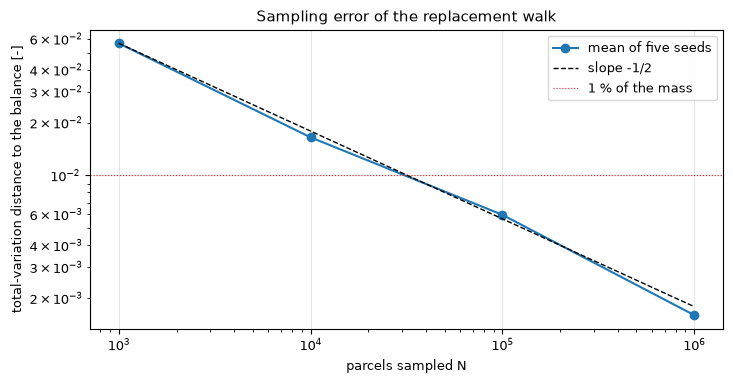

fitted slope: -0.509


In [8]:
# Plot the mean distance on logarithmic axes with the 1 / sqrt(N) law through the first point
mean_distance = np.array([np.mean(distance[s]) for s in sizes])
fig, ax = plt.subplots()
ax.loglog(sizes, mean_distance, "o-", label="mean of five seeds")
ax.loglog(sizes, mean_distance[0] * np.sqrt(sizes[0] / np.array(sizes)), "k--", lw=1, label="slope -1/2")
ax.axhline(0.01, color="tab:red", lw=0.8, ls=":", label="1 % of the mass")
ax.set_xlabel("parcels sampled N")
ax.set_ylabel("total-variation distance to the balance [-]")
ax.set_title("Sampling error of the replacement walk")
ax.legend()
fig.tight_layout()
plt.show()
slope = np.polyfit(np.log(sizes), np.log(mean_distance), 1)[0]
print("fitted slope:", round(float(slope), 3))

The measured distance falls with a slope close to $-1/2$, the law of Monte Carlo sampling, and it crosses the 1 percent line between $10^4$ and $10^5$ parcels. The walk therefore converges to the balance at the standard rate, and there is no bias to find at this resolution, as the expectation of Step 2 requires. The figure does not say that the balance is correct for a real crusher. It says that the balance is what the replacement rule gives when the rule is fed the same $C$ and $B$, so the whole difference between a particle-replacement simulation and this product lies in where $C$ and $B$ come from: the DEM derives them from contact mechanics and the chamber's geometry, while the product takes published forms whose constants, on the synthetic lane of S01, are the engine's own choices (provisional literature-typical K1 and K2 slopes and an energy constant with no published source, notebook 01) and only on the HP500 lane come from a calibration to plant surveys.

**Step 7, other settings and ores.** One operating point could be a coincidence of the numbers. The cell repeats the comparison for three closed-side settings and three ore hardnesses, nine combinations, each with its own selection vector and breakage matrix from `assemble_chamber`, 100 000 parcels and one seed, and prints the total-variation distance of the walk to the balance for each, together with the largest relative gap in the product P80.

In [9]:
# Total-variation distance of the walk to the balance for three settings and three ore hardnesses
print("CSS [mm]   A*b = 30    A*b = 55    A*b = 110")
worst_distance, p80_gap = 0.0, 0.0
for css in (op.css_mm * 0.7, op.css_mm, op.css_mm * 1.3):
    row = []
    for axb in (30, 55, 110):
        cc, BB = assemble_chamber(replace(op, css_mm=css, ore_axb=axb))
        ref = np.array(whiten_solve(cc.tolist(), BB.ravel().tolist(), feed.tolist(), K).product)
        product_walk = replacement_walk(cc, BB, feed, 100_000, 7)[0]
        row.append(0.5 * np.abs(product_walk - ref).sum())
        p80_walk = size_at_passing(to_psd(edges, product_walk.tolist()), 0.8)
        p80_gap = max(p80_gap, abs(p80_walk / size_at_passing(to_psd(edges, ref.tolist()), 0.8) - 1))
    worst_distance = max(worst_distance, *row)
    print(f"{css:7.1f}  " + "  ".join(f"{v:10.5f}" for v in row))
print("worst of the nine:", round(worst_distance, 5), "| largest relative P80 gap:", f"{p80_gap * 100:.3f} %")

CSS [mm]   A*b = 30    A*b = 55    A*b = 110
   22.4     0.00685     0.00567     0.00523
   32.0     0.00542     0.00478     0.00351
   41.6     0.00519     0.00540     0.00482
worst of the nine: 0.00685 | largest relative P80 gap: 0.295 %


All nine distances are of the same small size, a few thousandths, so the agreement is a property of the rule and not of S01's numbers, exactly as the algebra says. The table has one seed per cell, and its values, 0.00351 to 0.00685, overlap the five-seed spread printed above for S01 at the same 100 000 parcels (0.00396 to 0.00719); the order is not monotone either (at 41.6 mm, A*b = 55 gives 0.00540 against 0.00519 for A*b = 30). So at this resolution the distance shows no dependence on the setting or the ore. The last cell translates the distance into the number a plant cares about, the product P80, read by the same interpolation as the engine's, and compares it with the engine's own value over five seeds.

In [10]:
# P80 of the walk's product by the engine's interpolation, against the engine's P80
walk_p80 = []
for seed in range(5):
    product = replacement_walk(c, B, feed, 100_000, seed)[0]
    walk_p80.append(size_at_passing(to_psd(edges, product.tolist()), 0.8))
worst_gap = max(abs(v - result.p80) for v in walk_p80) / result.p80 * 100
print("P80 of the walk over five seeds [mm]:", np.round(walk_p80, 3))
print("engine P80 [mm]:", round(result.p80, 3), "| largest relative difference:", f"{worst_gap:.3f} %")

P80 of the walk over five seeds [mm]: [27.811 27.617 27.795 27.704 27.686]
engine P80 [mm]: 27.698 | largest relative difference: 0.409 %


The P80 of five independent walks of 100 000 parcels scatters around the engine's value by a few tenths of a percent, which is the scale a plant would never notice and the scale at which the walk stops being worth its extra cost. The five values do not drift to one side of the engine's, which is what an unbiased sampler looks like. This is the practical use of the walk: it prices the sampling error of a replacement-type simulation, in parcels, against a balance that costs a millisecond.

### Where the sampling breaks: the thin classes of the product

The total-variation distance is an average over the classes, and it hides where the walk is weakest. By the variance above, the relative error of a class share is about $\sqrt{2(1 - p_i) / (\pi N p_i)}$, so it grows as the share of the class falls: the thin classes at the fine end of the product, the ones that set a P10 or the fines of a downstream screen, are sampled worst. The cell first sets the law's prediction $\kappa / \sqrt N$ beside the five-seed means of Step 6, and then measures the relative error of every product class over five walks of 100 000 parcels against its share, with the predicted curve drawn through them.

    1,000 parcels: predicted 0.05322 | measured mean of five seeds 0.05660
   10,000 parcels: predicted 0.01683 | measured mean of five seeds 0.01649
  100,000 parcels: predicted 0.00532 | measured mean of five seeds 0.00597
1,000,000 parcels: predicted 0.00168 | measured mean of five seeds 0.00160


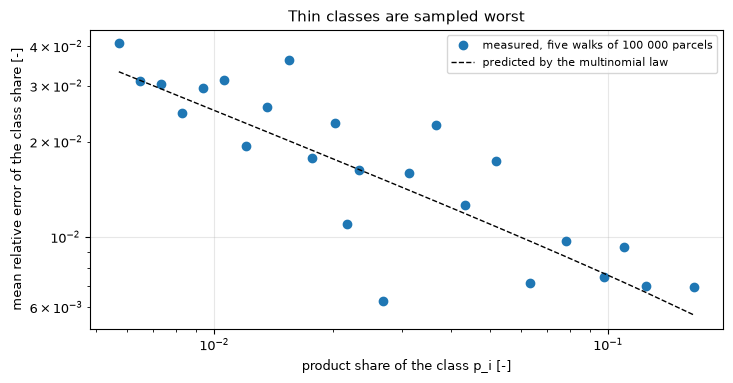

thinnest class: 0.00572 | its relative error: 0.0409
thickest class: 0.16534 | its relative error: 0.007


In [11]:
# The multinomial law against the measured distances of Step 6, then the relative error of each product class
kappa = 0.5 * np.sqrt(2 * reference * (1 - reference) / np.pi).sum()
for n_parcels in sizes:
    predicted, measured = kappa / np.sqrt(n_parcels), np.mean(distance[n_parcels])
    print(f"{n_parcels:>9,d} parcels: predicted {predicted:.5f} | measured mean of five seeds {measured:.5f}")
runs = np.array([replacement_walk(c, B, feed, 100_000, seed)[0] for seed in range(5)])
held = reference > 0
share = reference[held]
relative = np.abs(runs[:, held] - share).mean(axis=0) / share
order = np.argsort(share)
fig, ax = plt.subplots()
ax.loglog(share, relative, "o", label="measured, five walks of 100 000 parcels")
ax.loglog(share[order], np.sqrt(2 * (1 - share[order]) / (np.pi * 100_000 * share[order])), "k--", lw=1,
          label="predicted by the multinomial law")
ax.set_xlabel("product share of the class p_i [-]")
ax.set_ylabel("mean relative error of the class share [-]")
ax.set_title("Thin classes are sampled worst")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("thinnest class:", round(float(share.min()), 5), "| its relative error:", round(float(relative[order[0]]), 4))
print("thickest class:", round(float(share.max()), 5), "| its relative error:", round(float(relative[order[-1]]), 4))

The prediction matches the measurement at every budget to within the spread of five seeds, without any fitting: 0.0532 predicted against 0.0566 measured at 1 000 parcels and 0.00168 against 0.00160 at a million, so the convergence of the walk is not only of the right slope but of the right size. The figure shows the cost hidden in the average. The thickest classes of the S01 product, near 16 percent of the mass, are sampled to a fraction of a percent; the thinnest, under one percent of the mass, carry relative errors several times larger, and the measured points scatter around the dashed line because each is an average of only five walks. A replacement simulation sized to get the average right is therefore not sized to get the fines right, and a reader who needs a fine-end statistic has to budget the parcels for the thinnest class it reads, not for the total.

### Using it on your own data: a parcel budget for a tolerance

The law turns into a budget. For a tolerance $\varepsilon$ on the total-variation distance, $N \approx (\kappa / \varepsilon)^2$ parcels are needed, and $\kappa$ needs only the balance's product, which costs a millisecond. A developer who plans a replacement-type simulation of a chamber, or who wants to know how many parcels a sampled product needs before it is reported, builds the operating point, asks `assemble_chamber` for $c$ and $B$, solves the balance with `whiten_solve`, computes $\kappa$ and the budget, and runs one walk at that budget to check that it lands inside the tolerance. The cell does it for S01 and for the tertiary cone of notebook 02 with a tolerance of half a percent of the mass.

In [12]:
# Parcel budget for a tolerance on the total-variation distance, then one walk at that budget to check it
tolerance = 0.005
tertiary = replace(op, machine="cone-tert", css_mm=12.0, throw_mm=16.0, speed_rpm=400.0, feed_x63_mm=30.0,
                   feed_m=1.3, ore_axb=32.0, ore_wi=16.5)
for label, point in (("S01", op), ("tertiary cone", tertiary)):
    cc, BB = assemble_chamber(point)
    ff = np.array(evaluate(point).feed.mass)
    ref = np.array(whiten_solve(cc.tolist(), BB.ravel().tolist(), ff.tolist(), K).product)
    k = 0.5 * np.sqrt(2 * ref * (1 - ref) / np.pi).sum()
    budget = int(np.ceil((k / tolerance) ** 2))
    got = 0.5 * np.abs(replacement_walk(cc, BB, ff, budget, 11)[0] - ref).sum()
    print(f"{label:14s} kappa {k:.4f} | budget {budget:,d} parcels | distance of one walk {got:.5f}")

S01            kappa 1.6830 | budget 113,301 parcels | distance of one walk 0.00700
tertiary cone  kappa 1.5261 | budget 93,154 parcels | distance of one walk 0.00327


The two chambers need budgets of the same order, about a hundred thousand parcels for half a percent, because $\kappa$ depends on how the product's mass spreads over the classes and the two products spread it similarly; a product concentrated in fewer classes would need fewer parcels. One walk at each budget lands on either side of the tolerance, 0.00700 for S01 and 0.00327 for the cone, which is what a budget built on the expected distance means: a walk is one draw around that expectation, and a good share of the walks land above it, and a reader who needs a guarantee rather than an expectation should multiply the budget by a safety factor, for example four for twice the margin. The budget prices the sampling only. A discrete-element simulation spends its hours on contact mechanics, not on the count of fragments, so this number bounds the statistical part of its error and says nothing about the physics.

## Results

**Answer:** yes, and by construction. The expectation of the replacement rule is the Whiten product (Step 2), so what the runs measure is the sampling error. With 200 000 parcels the largest class-mass difference to the balance is 0.00168 and the total-variation distance 0.00372, and the walk counts 0.8843 nip events per parcel against the balance's 0.8858. The distance falls with a fitted slope of -0.509 as the number of parcels grows, from a mean of 0.01649 at 10 000 parcels to 0.00597 at 100 000, so it crosses 1 percent of the mass between the two. Over nine combinations of setting and ore the worst distance is 0.00685 and the worst P80 gap 0.295 percent, and the P80 of five walks of 100 000 parcels stays within 0.409 percent of the engine's 27.698 mm. A budget of 100 000 parcels therefore gives the product within a few tenths of a percent of the mass.

The first figure shows the product class by class, the second the convergence law. A validator would conclude that the product's fast model and the replacement rule of the discrete-element family share their algebra, and that the sampling error of the rule is controlled and standard. The honest limits are three. The walk does not reproduce any number of Cleary and Sinnott (2015) or Quist and Evertsson (2016): no code or data of theirs is here, and discrete-element simulation is not a method of this release. It has no geometry, no contact mechanics, no wear and no particle shapes, which are what a discrete-element simulation buys with its hours of computation. And the agreement is of the rule, not of the constants: whether $C$ and $B$ describe a given crusher is settled against measurements, in topics 05 and 06.

## Summary

The population balance is the exact expectation of the particle-replacement rule, the walk is its Monte Carlo sampling, and their gap shrinks as the inverse square root of the number of parcels. What the discrete element method adds is the physics that produces $C$ and $B$, not a different algebra, and that physics is not in this release. The studio keeps the cheap form, so that a reader can move a slider and see a product in a millisecond, and it is explicit that its $C$ and $B$ are not derived: on the synthetic lane of S01 they are published forms with the engine's chosen constants, and only on the HP500 lane are they fitted to plant surveys. Topic 04 takes the power side of the model: capacity, setting and energy.

The size of that gap is predicted by the multinomial law before any walk runs, which turns it into a parcel budget, and the thin classes of the fine end are where a sampled product is least reliable.

## References

- Cleary, P. W., Sinnott, M. D. (2015), Simulation of particle flows and breakage in crushers using DEM: Part 1 - Compression crushers, Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Quist, J., Evertsson, C. M. (2016), Cone crusher modelling and simulation using DEM, Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, in Proceedings of the APCOM 1972 symposium (Application of Computer Methods in the Mineral Industry), South African Institute of Mining and Metallurgy, 317-324. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193